# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

**Method: Hagan–West style monotone convex interpolation through the nodes.** Hagan–West build a local curve from interval averages. When one quadratic on an interval would not be monotone, they split the interval into two quadratics at a break point. The brief requires the curve to **pass through the supplied IFR points**, so this implementation keeps the same ideas but applies them to the **slope** of the curve. On an interval of width $h$ with node values $y_0, y_1$ and secant slope $d=(y_1-y_0)/h$:

1. **Node slopes** use the Hagan–West weights of eq. (22): $m_i=\dfrac{h_i d_{i-1}+h_{i-1}d_i}{h_{i-1}+h_i}$ if the two neighbouring secants have the same sign, otherwise $m_i=0$ (the data turns there). **End nodes:** slope $0$ where the curve can join the flat extrapolation smoothly; Hagan–West choose their end values (23)/(24) for the same reason ($f'=0$ at the ends). Otherwise $m_0=2d_0-m_1$, so the two end slopes of the first interval average to its secant.
2. **Clip** each interval's end slopes so that $s_0\le d\le s_1$ (the slope only rises → **convex**) and $s_0,s_1$ have the sign of $d$ (the slope never changes sign → **monotone**).
3. **Two parabolas:** the slope moves linearly $s_0\to d$ up to a break point $k=h\,\frac{s_1-d}{s_1-s_0}$, then $d\to s_1$. The mean slope is $d$, so the curve **ends exactly at $y_1$**, and $f''\ge 0$ on both pieces.
4. **Integral:** each piece is a quadratic, so $\int f$ and the discount factors $e^{-\int f}$ are exact. Extrapolation is FLAT, so a one-node curve is constant.

**Result.** The two pieces meet at the break point and pass through both nodes, so the curve is **continuous by construction**. It passes through every point and is monotone and convex on every node interval. For convex data, such as the supplied SOFR and FF, nothing is clipped and the curve is also smooth ($C^1$).

**Data that cannot satisfy all conditions** (e.g. a hump, right panel of the plot below): no curve can be convex on both sides of a turning node *and* smooth there. Continuity, the node values, and monotonicity and convexity on each interval are kept; smoothness is given up. The slopes are clipped and the curve has a kink at that node (at worst an interval becomes a straight line). Duplicate node times are dropped; non-finite input and non-FLAT extrapolation raise an error.

*Note:* the curve matches the supplied points rather than PCP's interval averages, so discount factors differ from PCP's. That difference is what the pricing cells below measure.

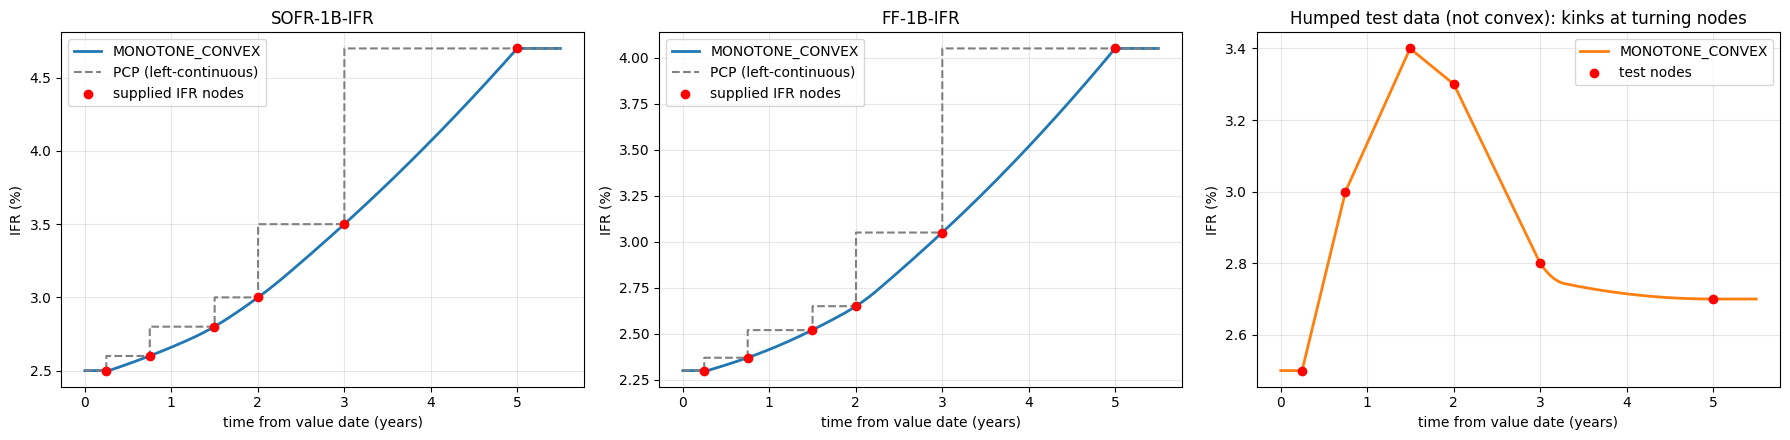

SOFR: passes through nodes=True, monotone=True, convex=True on each interval; max slope jump at a node=2.7e-09
FF: passes through nodes=True, monotone=True, convex=True on each interval; max slope jump at a node=3.4e-09
Hump (test data): passes through nodes=True, monotone=True, convex=True on each interval; max slope jump at a node=7.3e-03


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from fixedincomelib.date import Date, accrued
from fixedincomelib.utilities import InterpolatorFactory, InterpMethod, ExtrapMethod

MC, PCP, FLAT = InterpMethod.MONOTONE_CONVEX, InterpMethod.PIECEWISE_CONSTANT_LEFT_CONTINUOUS, ExtrapMethod.FLAT

# Node times in years, using the same convention as the model
value_date = Date("2026-01-02")
node_t = np.array([accrued(value_date, Date(d)) for d in node_dates])
grid = np.linspace(0.0, node_t[-1] + 0.5, 800)

# Check: the pricing model's SOFR curve is this class, on these node times
mc_build = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {**inputs, "INTERPOLATION METHOD": "MONOTONE_CONVEX", "EXTRAPOLATION METHOD": "FLAT"})
    for kind, inputs in curve_inputs
])
mc_model = qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, mc_build)
model_curve = mc_model.retrieve_model_component("SOFR-1B").state_data_interpolator
assert type(model_curve).__name__ == "Interpolator1DMonotoneConvex"
assert np.allclose(model_curve.axis1, node_t)

# Humped test data on the same nodes: it rises then falls, so it cannot be convex at every node
hump_vals = np.array([0.025, 0.030, 0.034, 0.033, 0.028, 0.027])
hump = InterpolatorFactory.create_1d_interpolator(node_t, hump_vals, MC, FLAT)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name, quotes in zip(axes[:2], ["SOFR-1B-IFR", "FF-1B-IFR"], [sofr_quotes, ff_quotes]):
    vals = quotes["values"].values
    mc = InterpolatorFactory.create_1d_interpolator(node_t, vals, MC, FLAT)
    pcp = InterpolatorFactory.create_1d_interpolator(node_t, vals, PCP, FLAT)
    ax.plot(grid, [100 * mc.interpolate(t) for t in grid], lw=2, label="MONOTONE_CONVEX")
    ax.step(grid, [100 * pcp.interpolate(t) for t in grid], where="post", ls="--", color="gray",
            label="PCP (left-continuous)")
    ax.scatter(node_t, 100 * vals, color="red", zorder=5, label="supplied IFR nodes")
    ax.set_title(name)

ax = axes[2]
ax.plot(grid, [100 * hump.interpolate(t) for t in grid], lw=2, color="C1", label="MONOTONE_CONVEX")
ax.scatter(node_t, 100 * hump_vals, color="red", zorder=5, label="test nodes")
ax.set_title("Humped test data (not convex): kinks at turning nodes")

for ax in axes:
    ax.set_xlabel("time from value date (years)")
    ax.set_ylabel("IFR (%)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


def check(curve, nodes, vals):
    """Check the required properties on every node interval (continuity holds by construction)."""
    hits_nodes = max(abs(curve.interpolate(t) - v) for t, v in zip(nodes, vals)) < 1e-14
    monotone = convex = True
    for a, b in zip(nodes[:-1], nodes[1:]):
        f = np.array([curve.interpolate(t) for t in np.linspace(a, b, 200)])
        monotone &= bool(np.all(np.diff(f) >= -1e-12) or np.all(np.diff(f) <= 1e-12))
        convex &= bool(np.all(np.diff(f, 2) >= -1e-10))
    # slope jump at the interior nodes: about 0 means smooth, larger means a kink
    e = 1e-6
    kink = max(abs(curve.interpolate(t + e) - 2 * curve.interpolate(t) + curve.interpolate(t - e)) / e
               for t in nodes[1:-1])
    return (f"passes through nodes={hits_nodes}, monotone={monotone}, convex={convex} on each interval; "
            f"max slope jump at a node={kink:.1e}")


for name, quotes in [("SOFR", sofr_quotes), ("FF", ff_quotes)]:
    vals = quotes["values"].values
    print(f"{name}: " + check(InterpolatorFactory.create_1d_interpolator(node_t, vals, MC, FLAT), node_t, vals))
print("Hump (test data): " + check(hump, node_t, hump_vals))


In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3267.1271708331933
Student minus PCP: 358.84053159522955


**FRA result.** MONOTONE_CONVEX PV is about **+359** higher than PCP (3,267.13 vs 2,908.29). The window (2026-05-05 to 2026-11-05) lies on rising IFR data. PCP is left-continuous, so it uses the *right-node* rate for the whole interval (2.6% until 2026-10-02, then 2.8%): the highest rate of each interval. The monotone-convex curve passes through the same nodes but moves smoothly between them, so it is lower inside the interval. Over the FRA window the average SOFR forward is 2.64% with PCP and 2.57% with monotone convex. A lower forward makes a receive-fixed FRA worth more.

In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069761


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12852.785707786214
Student minus PCP: 6630.268194716453


**RFR swap result.** The monotone-convex PV is about **+6,630** higher than PCP (12,852.79 vs 6,222.52). Same reason, but over three years and with steeper rising data: the average SOFR forward over the swap's life is 3.19% with PCP and 2.96% with monotone convex. The effect is largest in the last year (2028-04-02 to 2029-04-02), which runs up to the 2029-01-02 node and just past it, where PCP already uses the next node's rate: the average forward is 3.80% with PCP and 3.37% with monotone convex. Lower floating forwards cut the floating leg and raise the PV of the receive-fixed swap (the funding/discount curve also changes, but that effect is much smaller).

In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181775


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV:

 7623.189411015832
Student minus PCP: -728.1594971659433


**Overnight basis swap result.** The monotone-convex PV is about **-728** lower than PCP (7,623.19 vs 8,351.35). The swap receives SOFR + 10bp and pays Fed Funds, so what matters is the SOFR minus FF gap. That gap widens with maturity, and PCP uses the right node's (largest) gap over each interval. Over the life of the swap the average gap is 33.4bp with PCP and 29.5bp with monotone convex, so the received SOFR leg is worth less relative to the paid FF leg and the PV falls. The difference is under 10% of the PV because both legs move in the same direction.

### PV summary (computed from the cells above)

In [9]:
summary = pd.DataFrame({
    "PCP PV": [fra_pcp_pv, swap_pcp_pv, basis_pcp_pv],
    "MONOTONE_CONVEX PV": [fra_student_pv, swap_student_pv, basis_student_pv],
}, index=["FRA (receive fixed)", "RFR swap (receive fixed)", "Basis swap (receive SOFR+10bp, pay FF)"])
summary["Difference"] = summary["MONOTONE_CONVEX PV"] - summary["PCP PV"]
summary.round(2)

,PCP PV,MONOTONE_CONVEX PV,Difference
FRA (receive fixed),2908.29,3267.13,358.84
RFR swap (receive fixed),6222.52,12852.79,6630.27
"Basis swap (receive SOFR+10bp, pay FF)",8351.35,7623.19,-728.16
